In [5]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


# Hệ thống Phân tích Nội dung TikTok & Cảm xúc Bình luận

- **Giai đoạn 1 (`gemma4-e2b-opt` trên Ollama):** Đọc video (có âm thanh hoặc không có âm thanh) hoặc hình ảnh TikTok để trích xuất **chủ đề chính, quan điểm, tóm tắt, từ khóa**.
- **Giai đoạn 2 (`5CD-AI/Vietnamese-Sentiment-visobert`):** Thuần Deep Learning phân loại bình luận tiếng Việt MXH thành 3 nhãn: **Tích cực (`POS`)**, **Tiêu cực (`NEG`)**, **Trung tính (`NEU`)**.

> Đảm bảo container Ollama `gemma4-e2b` đang chạy (`docker compose up -d` trong `AI_Local/gemma4-e2b`) trước khi chạy Giai đoạn 1.

In [6]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.comment_classifier import CommentClassifier
from src.media_analyzer import MediaAnalyzer
from src.pipeline import SentimentPipeline, load_comments, plot_sentiment_summary

# === CẤU HÌNH ĐẦU VÀO ===
# Thay bằng đường dẫn tới file video (.mp4, .mov...), file ảnh (.jpg, .png...) hoặc thư mục chứa nhiều ảnh
MEDIA_PATH = r"G:\Download\Download (1).mp4"
CAPTION = ""  # Caption bài đăng TikTok (nếu có)
ENABLE_AUDIO = True  # Tự động nhận diện âm thanh & bóc lời thoại tiếng Việt

# File bình luận (.csv, .json, .txt). Mặc định dùng bộ mẫu có sẵn
COMMENTS_PATH = r"data\tiktok.csv"

# Chạy ViSoBERT trên "cpu" để tránh tranh chấp 4GB VRAM với Ollama (hoặc "auto" nếu muốn dùng GPU)
DEVICE = "cpu"
OUTPUT_DIR = Path("outputs")

In [7]:
# === GIAI ĐOẠN 1: PHÂN TÍCH VIDEO / ẢNH BẰNG GEMMA 4 E2B ===
analyzer = MediaAnalyzer(
    ollama_url="http://localhost:11434",
    model_name="gemma4-e2b-opt",
    whisper_model="small",
    max_frames=10,
    image_size=512,
)

if MEDIA_PATH and Path(MEDIA_PATH).exists():
    media_result = analyzer.analyze(
        media_input=MEDIA_PATH,
        caption=CAPTION,
        enable_audio=ENABLE_AUDIO,
    )
    print(json.dumps(media_result.to_dict(), ensure_ascii=False, indent=2))
else:
    media_result = None
    print(f"[Thông báo] Không tìm thấy file media tại: {MEDIA_PATH}. Hãy cập nhật MEDIA_PATH để chạy Giai đoạn 1.")

{
  "media_type": "video",
  "source_paths": [
    "G:\\Download\\Download (1).mp4"
  ],
  "num_frames_used": 10,
  "has_audio": true,
  "transcript": "Siêu tổng hợp đồ da mai trường găng phần 1 Ngoài, chiếc còn cửa như anh em mình là bé không biết Thì mình phải xem lại mình đó Chẳng hãy nói luôn này Bây giờ ra đường người ta vẫn kêu là trấn thành đó Bây giờ ra đường người ta vẫn kêu là trấn thành đó Oh Có rất nhiều người kêu anh là trấn thành Không em nghĩ lâu lâu một bé thôi Bây giờ mà một bé tiếp theo mà không biết anh em mình là mình phải coi lợi Coi lại đó nha, chứ không phải được Chuyện trường điệp 2 người hay quá Phải đối thật vòng là anh Hàn sẽ mãi luôn Em mong là tụi em mà đi anh Hàn là em phải được đi anh Hàn Chắc gì sắp tụi người đó",
  "chu_de_chinh": "Tổng hợp drama/tin tức",
  "quan_diem_noi_dung": "Chia sẻ thông tin, mong muốn được tham gia hoặc quan tâm đến một sự kiện/nhân vật nào đó.",
  "tom_tat_ngan": "Video này là một bản tổng hợp (siêu tổng hợp) về một drama hoặc 

In [8]:
# === GIAI ĐOẠN 2: PHÂN LOẠI COMMENT BẰNG VISOBERT ===
comments = load_comments(COMMENTS_PATH)
print(f"Đã nạp {len(comments)} bình luận từ {COMMENTS_PATH}")

classifier = CommentClassifier(device=DEVICE, batch_size=32)
predictions = classifier.predict_batch(comments, show_progress=True)

df_comments = pd.DataFrame(
    [
        {
            "Bình luận gốc": p.original_text,
            "Nhãn": p.label,
            "Cảm xúc": p.label_vi,
            "Độ tự tin": p.confidence,
            "POS": p.scores["POS"],
            "NEU": p.scores["NEU"],
            "NEG": p.scores["NEG"],
        }
        for p in predictions
    ]
)
df_comments.head(15)

Đã nạp 198 bình luận từ data\tiktok.csv


Phân loại comment: 100%|██████████| 7/7 [00:10<00:00,  1.43s/batch]


,Bình luận gốc,Nhãn,Cảm xúc,Độ tự tin,POS,NEU,NEG
0,Coi riết t thù luôn chứ không ghét nữa,POS,Tích cực,0.9933,0.9933,0.0000,0.0066
1,Giống điểm gì 😅,POS,Tích cực,0.9990,0.9990,0.0001,0.0010
2,"hổng ai kêu anh là TT hết á, Hai của tui cao r...",POS,Tích cực,0.9974,0.9974,0.0012,0.0013
3,Kêu anh là trấn thành chi vậy anh,POS,Tích cực,0.9992,0.9992,0.0005,0.0002
4,gần tháng này chưa xem cái nào trùng cái nào l...,POS,Tích cực,0.9987,0.9987,0.0002,0.0011
5,Mình là người luôn giữ lập trường ai nói gì nó...,POS,Tích cực,0.9997,0.9997,0.0002,0.0001
6,Nhưng Trấn Thành k bị nhầm là trường giang,POS,Tích cực,0.9962,0.9962,0.0036,0.0002
7,gì má,NEG,Tiêu cực,0.9841,0.0151,0.0008,0.9841
8,Ụa rồi mắc gì căng. 🤣,POS,Tích cực,0.9996,0.9996,0.0001,0.0003
9,Dị đó mà ảnh lập vi bằng đó,POS,Tích cực,0.9981,0.9981,0.0004,0.0015


Tổng hợp cảm xúc:
{
  "total_comments": 198,
  "counts": {
    "POS": 162,
    "NEG": 27,
    "NEU": 9
  },
  "percentages": {
    "POS": 81.82,
    "NEG": 13.64,
    "NEU": 4.55
  },
  "avg_confidence": 0.9491,
  "overall_tendency": "Tích cực",
  "top_examples": {
    "POS": [
      {
        "comment": "Trấn Thành nào á chớ 🤣🤣🤣",
        "confidence": 0.9998
      },
      {
        "comment": "TG nói chuyện có duyên",
        "confidence": 0.9998
      },
      {
        "comment": "Ờ giống Trấn Thành lắm rồi đó he 🙂",
        "confidence": 0.9998
      }
    ],
    "NEG": [
      {
        "comment": "Ko muốn xem vì sợ ghét quá 🙄",
        "confidence": 0.9983
      },
      {
        "comment": "đã coi qua 2 3 lần nhưng xem lại vẫn cay cú và ghéc khó chịu quá",
        "confidence": 0.9981
      },
      {
        "comment": "sáng ra xem tụt năng lượng vcl",
        "confidence": 0.9981
      }
    ],
    "NEU": [
      {
        "comment": "tao thấy bình thường",
        "confide

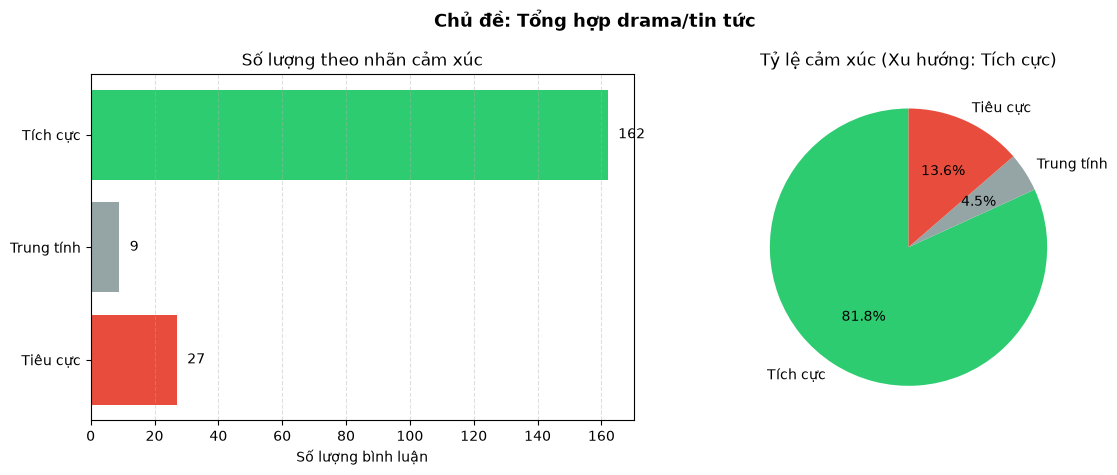

In [9]:
# === TỔNG HỢP KẾT QUẢ & VẼ BIỂU ĐỒ ===
summary = classifier.summarize(predictions, top_k=3)
print("Tổng hợp cảm xúc:")
print(json.dumps(summary, ensure_ascii=False, indent=2))

preview_report = {
    "media_analysis": media_result.to_dict() if media_result else None,
    "sentiment_summary": summary,
    "comments": [p.to_dict() for p in predictions],
}
fig = plot_sentiment_summary(preview_report)
plt.show()

In [10]:
# === CHẠY TRỌN BỘ PIPELINE VÀ XUẤT BÁO CÁO RA FILE ===
pipeline = SentimentPipeline(
    media_analyzer=analyzer,
    comment_classifier=classifier,
)

active_media = MEDIA_PATH if (MEDIA_PATH and Path(MEDIA_PATH).exists()) else None
report = pipeline.run(
    media_input=active_media,
    comments_source=COMMENTS_PATH,
    caption=CAPTION,
    enable_audio=ENABLE_AUDIO,
    output_dir=OUTPUT_DIR,
    show_progress=False,
)

print(f"Đã xuất báo cáo JSON và CSV vào thư mục: {OUTPUT_DIR.resolve()}")

Đã xuất báo cáo JSON và CSV vào thư mục: E:\A\Sentiment-Analysis\outputs
